In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!nvidia-smi

Wed Mar 20 17:04:07 2024       
+---------------------------------------------------------------------------------------+
| NVIDIA-SMI 535.104.05             Driver Version: 535.104.05   CUDA Version: 12.2     |
|-----------------------------------------+----------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |         Memory-Usage | GPU-Util  Compute M. |
|                                         |                      |               MIG M. |
|=========================================+======================+======================|
|   0  Tesla T4                       Off | 00000000:00:04.0 Off |                    0 |
| N/A   45C    P8               9W /  70W |      0MiB / 15360MiB |      0%      Default |
|                                         |                      |                  N/A |
+-----------------------------------------+----------------------+--

In [ ]:
#!apt-get install unrar

^C


In [ ]:
#!unrar x '/content/train.rar' '/content/drive/MyDrive/gproject/'


In [ ]:
#! du -sh /content/train.rar


712M	/content/train.rar


In [1]:

# import system libs
import os
import time
import shutil
import pathlib
import itertools


import tensorflow.keras.backend as K
# import data handling tools
import cv2
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_style('darkgrid')
import matplotlib.pyplot as plt

rom sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import f1_score


# import Deep learning Libraries
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam, Adamax
from tensorflow.keras.metrics import categorical_crossentropy
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras import regularizers
# Import GPU-related libraries
from tensorflow.compat.v1 import ConfigProto
from tensorflow.compat.v1 import InteractiveSession

In [3]:
# Configure GPU settings
config = ConfigProto()
config.gpu_options.allow_growth = True
session = InteractiveSession(config=config)
# Limit GPU Memory Growth
gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)
# Ignore Warnings
import warnings
warnings.filterwarnings("ignore")

print('modules loaded')

modules loaded


In [4]:

# Generate data paths with labels
def define_paths(data_dir):
    filepaths = []
    labels = []

    folds = os.listdir(data_dir)
    for fold in folds:
        foldpath = os.path.join(data_dir, fold)
        filelist = os.listdir(foldpath)
        for file in filelist:
            fpath = os.path.join(foldpath, file)
            filepaths.append(fpath)
            labels.append(fold)

    return filepaths, labels


In [5]:

# Concatenate data paths with labels into one dataframe (to later be fitted into the model)
def define_df(files, classes):
    Fseries = pd.Series(files, name='filepaths')
    Lseries = pd.Series(classes, name='labels')
    return pd.concat([Fseries, Lseries], axis=1)


In [6]:
def split_data(data_dir):
    # train dataframe
    files, classes = define_paths(data_dir)
    df = define_df(files, classes)
    strat = df['labels']
    train_df, valid_df = train_test_split(df, train_size=0.8, shuffle=True, random_state=123, stratify=strat)

    return train_df, valid_df

In [7]:
#     return train_gen, valid_gen

                                           color_mode=color, shuffle=True, batch_size=batch_size)

    valid_gen = ts_gen.flow_from_dataframe(valid_df, x_col='filepaths'def create_gens(train_df, valid_df, batch_size):
    '''
    This function takes train and validation dataframes and fits them into the image data generator,
    because the model takes data from the image data generator.
    Image data generator converts images into tensors.
    '''

    # define model parameters
    img_size = (224, 224)
    channels = 3  # either BGR or Grayscale
    color = 'rgb'
    img_shape = (img_size[0], img_size[1], channels)

    # test_batch_size = max(sorted([ts_length // n for n in range(1, ts_length + 1) if ts_length % n == 0 and ts_length / n <= 80]))
    # test_steps = ts_length // test_batch_size

    # This function, which will be used in the image data generator for data augmentation,
    # just takes the image and returns it again.
    def scalar(img):
        return img

    tr_gen = ImageDataGenerator(preprocessing_function=scalar)
    ts_gen = ImageDataGenerator(preprocessing_function=scalar)

    train_gen = tr_gen.flow_from_dataframe(train_df, x_col='filepaths', y_col='labels', target_size=img_size,
                                           class_mode='categorical',, y_col='labels', target_size=img_size,
                                           class_mode='categorical',
                                           color_mode=color, shuffle=True, batch_size=batch_size)

    return train_gen, valid_gen # Recommended: use a custom function for the test data batch size; else, we can use the normal batch size.
    # ts_length = len(test_df)
   

In [8]:
def show_images(gen):
    '''
    This function takes the data generator and shows a sample of the images.
    '''

    # return classes , images to be displayed
    g_dict = gen.class_indices  # defines dictionary {'class': index}
    classes = list(g_dict.keys())  # defines list of dictionary's keys (classes), classes names: string
    images, labels = next(gen)  # get a batch size samples from the generator

    # calculate the number of displayed samples
    length = len(labels)  # length of batch size
    sample = min(length, 25)  # check if the sample is less than 25 images

    plt.figure(figsize=(20, 20))

    for i in range(sample):
        plt.subplot(5, 5, i + 1)
        image = images[i] / 255  # scales data to range (0 - 255)
        plt.imshow(image)
        index = np.argmax(labels[i])  # get image index
        class_name = classes[index]  # get class of the image
        plt.title(class_name, color='blue', fontsize=12)
        plt.axis('off')
    plt.show()


In [9]:
class MyCallback(keras.callbacks.Callback):
    def __init__(self, model, patience, stop_patience, threshold, factor, batches, epochs, ask_epoch):
        super(MyCallback, self).__init__()
        self.model = model
        self.patience = patience # specifies how many epochs without improvement before learning rate is adjusted
        self.stop_patience = stop_patience # specifies how many times to adjust lr without improvement to stop training
        self.threshold = threshold # specifies training accuracy threshold when lr will be adjusted based on validation loss
        self.factor = factor # factor by which to reduce the learning rate
        self.batches = batches # number of training batch to run per epoch
        self.epochs = epochs
        self.ask_epoch = ask_epoch
        self.ask_epoch_initial = ask_epoch # save this value to restore if restarting training

        # callback variables
        self.count = 0 # how many times lr has been reduced without improvement
        self.stop_count = 0
        self.best_epoch = 1   # epoch with the lowest loss
        self.initial_lr = float(tf.keras.backend.get_value(model.optimizer.lr)) # get the initial learning rate and save it
        self.highest_tracc = 0.0 # set highest training accuracy to 0 initially
        self.lowest_vloss = np.inf # set lowest validation loss to infinity initially
        self.best_weights = self.model.get_weights() # set best weights to model's initial weights
        self.initial_weights = self.model.get_weights()   # save initial weights if they have to get restored

    # Define a function that will run when train begins
    def on_train_begin(self, logs= None):
        msg = 'Do you want model asks you to halt the training [y/n] ?'
        print(msg)
        ans = input('')
        if ans in ['Y', 'y']:
            self.ask_permission = 1
        elif ans in ['N', 'n']:
            self.ask_permission = 0

        msg = '{0:^8s}{1:^10s}{2:^9s}{3:^9s}{4:^9s}{5:^9s}{6:^9s}{7:^10s}{8:10s}{9:^8s}'.format('Epoch', 'Loss', 'Accuracy', 'V_loss', 'V_acc', 'LR', 'Next LR', 'Monitor','% Improv', 'Duration')
        print(msg)
        self.start_time = time.time()


    def on_train_end(self, logs= None):
        stop_time = time.time()
        tr_duration = stop_time - self.start_time
        hours = tr_duration // 3600
        minutes = (tr_duration - (hours * 3600)) // 60
        seconds = tr_duration - ((hours * 3600) + (minutes * 60))

        msg = f'training elapsed time was {str(hours)} hours, {minutes:4.1f} minutes, {seconds:4.2f} seconds)'
        print(msg)

        # set the weights of the model to the best weights
        self.model.set_weights(self.best_weights)


    def on_train_batch_end(self, batch, logs= None):
        # get batch accuracy and loss
        acc = logs.get('accuracy') * 100
        loss = logs.get('loss')

        # prints over on the same line to show running batch count
        msg = '{0:20s}processing batch {1:} of {2:5s}-   accuracy=  {3:5.3f}   -   loss: {4:8.5f}'.format(' ', str(batch), str(self.batches), acc, loss)
        print(msg, '\r', end= '')


    def on_epoch_begin(self, epoch, logs= None):
        tf.keras.backend.clear_session()
        self.ep_start = time.time()


    # Define method runs on the end of each epoch
    def on_epoch_end(self, epoch, logs= None):
        ep_end = time.time()
        duration = ep_end - self.ep_start

        lr = float(tf.keras.backend.get_value(self.model.optimizer.lr)) # get the current learning rate
        current_lr = lr
        acc = logs.get('accuracy')  # get training accuracy
        v_acc = logs.get('val_accuracy')  # get validation accuracy
        loss = logs.get('loss')  # get training loss for this epoch
        v_loss = logs.get('val_loss')  # get the validation loss for this epoch
        # Assuming you have TP, FP, FN in your logs
        # TP = logs.get('true_positives')  # Replace with the actual key in your logs
        # FP = logs.get('false_positives')  # Replace with the actual key in your logs
        # FN = logs.get('false_negatives')  # Replace with the actual key in your logs

        # # Calculate precision and recall
        # precision = TP / (TP + FP) if TP + FP > 0 else 0
        # recall = TP / (TP + FN) if TP + FN > 0 else 0

        # # Calculate F1 score
        # f1_score_value = 2 * (precision * recall) / (precision + recall) if precision + recall > 0 else 0

        # # Print or use the F1 score as needed
        # print(f'F1 Score: {f1_score_value}')

        if acc < self.threshold: # if training accuracy is below threshold adjust lr based on training accuracy
            monitor = 'accuracy'
            if epoch == 0:
                pimprov = 0.0
            else:
                pimprov = (acc - self.highest_tracc ) * 100 / self.highest_tracc # define improvement of model progres

            if acc > self.highest_tracc: # training accuracy improved in the epoch
                self.highest_tracc = acc # set new highest training accuracy
                self.best_weights = self.model.get_weights() # training accuracy improved so save the weights
                self.count = 0 # set count to 0 since training accuracy improved
                self.stop_count = 0 # set stop counter to 0
                if v_loss < self.lowest_vloss:
                    self.lowest_vloss = v_loss
                self.best_epoch = epoch + 1  # set the value of best epoch for this epoch

            else:
                # training accuracy did not improve check if this has happened for patience number of epochs
                # if so adjust learning rate
                if self.count >= self.patience - 1: # lr should be adjusted
                    lr = lr * self.factor # adjust the learning by factor
                    tf.keras.backend.set_value(self.model.optimizer.lr, lr) # set the learning rate in the optimizer
                    self.count = 0 # reset the count to 0
                    self.stop_count = self.stop_count + 1 # count the number of consecutive lr adjustments
                    self.count = 0 # reset counter
                    if v_loss < self.lowest_vloss:
                        self.lowest_vloss = v_loss
                else:
                    self.count = self.count + 1 # increment patience counter

        else: # training accuracy is above threshold so adjust learning rate based on validation loss
            monitor = 'val_loss'
            if epoch == 0:
                pimprov = 0.0

            else:
                pimprov = (self.lowest_vloss - v_loss ) * 100 / self.lowest_vloss

            if v_loss < self.lowest_vloss: # check if the validation loss improved
                self.lowest_vloss = v_loss # replace lowest validation loss with new validation loss
                self.best_weights = self.model.get_weights() # validation loss improved so save the weights
                self.count = 0 # reset count since validation loss improved
                self.stop_count = 0
                self.best_epoch = epoch + 1 # set the value of the best epoch to this epoch

            else: # validation loss did not improve
                if self.count >= self.patience - 1: # need to adjust lr
                    lr = lr * self.factor # adjust the learning rate
                    self.stop_count = self.stop_count + 1 # increment stop counter because lr was adjusted
                    self.count = 0 # reset counter
                    tf.keras.backend.set_value(self.model.optimizer.lr, lr) # set the learning rate in the optimizer

                else:
                    self.count = self.count + 1 # increment the patience counter

                if acc > self.highest_tracc:
                    self.highest_tracc = acc

        msg = f'{str(epoch + 1):^3s}/{str(self.epochs):4s} {loss:^9.3f}{acc * 100:^9.3f}{v_loss:^9.5f}{v_acc * 100:^9.3f}{current_lr:^9.5f}{lr:^9.5f}{monitor:^11s}{pimprov:^10.2f}{duration:^8.2f}'
        print(msg)

        if self.stop_count > self.stop_patience - 1: # check if learning rate has been adjusted stop_count times with no improvement
            msg = f' training has been halted at epoch {epoch + 1} after {self.stop_patience} adjustments of learning rate with no improvement'
            print(msg)
            self.model.stop_training = True # stop training

        else:
            if self.ask_epoch != None and self.ask_permission != 0:
                if epoch + 1 >= self.ask_epoch:
                    msg = 'enter H to halt training or an integer for number of epochs to run then ask again'
                    print(msg)

                    ans = input('')
                    if ans == 'H' or ans == 'h':
                        msg = f'training has been halted at epoch {epoch + 1} due to user input'
                        print(msg)
                        self.model.stop_training = True # stop training

                    else:
                        try:
                            ans = int(ans)
                            self.ask_epoch += ans
                            msg = f' training will continue until epoch {str(self.ask_epoch)}'
                            print(msg)
                            msg = '{0:^8s}{1:^10s}{2:^9s}{3:^9s}{4:^9s}{5:^9s}{6:^9s}{7:^10s}{8:10s}{9:^8s}'.format('Epoch', 'Loss', 'Accuracy', 'V_loss', 'V_acc', 'LR', 'Next LR', 'Monitor', '% Improv', 'Duration')
                            print(msg)

                        except Exception:
                            print('Invalid')


In [10]:
def plot_training(hist):
    '''
    This function takes the training model and plots the history of accuracy and losses with the best epoch in both of them.
    '''

    # Define needed variables
    tr_acc = hist.history['accuracy']
    tr_loss = hist.history['loss']
    val_acc = hist.history['val_accuracy']
    val_loss = hist.history['val_loss']

    index_loss = np.argmin(val_loss)
    val_lowest = val_loss[index_loss]
    index_acc = np.argmax(val_acc)
    acc_highest = val_acc[index_acc]

    Epochs = [i + 1 for i in range(len(tr_acc))]

    loss_label = f'best epoch= {str(index_loss + 1)}'
    acc_label = f'best epoch= {str(index_acc + 1)}'

    # Plot training history
    plt.figure(figsize=(20, 8))
    plt.style.use('fivethirtyeight')

    plt.subplot(1, 2, 1)
    plt.plot(Epochs, tr_loss, 'r', label='Training loss')
    plt.plot(Epochs, val_loss, 'g', label='Validation loss')
    plt.scatter(index_loss + 1, val_lowest, s=150, c='blue', label=loss_label)
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(Epochs, tr_acc, 'r', label='Training Accuracy')
    plt.plot(Epochs, val_acc, 'g', label='Validation Accuracy')
    plt.scatter(index_acc + 1, acc_highest, s=150, c='blue', label=acc_label)
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.tight_layout
    plt.show()

In [11]:
pwd

'/content'

In [12]:
data_dir = '/content/drive/MyDrive/burns'

try:
    # Get training and validation data
    train_df, valid_df = split_data(data_dir)

    # Get Generators for training and validation
    batch_size = 40
    train_gen, valid_gen = create_gens(train_df, valid_df, batch_size)
except Exception as e:
    print(f'Error: {e}')

# =============================\


Found 1909 validated image filenames belonging to 3 classes.
Found 478 validated image filenames belonging to 3 classes.


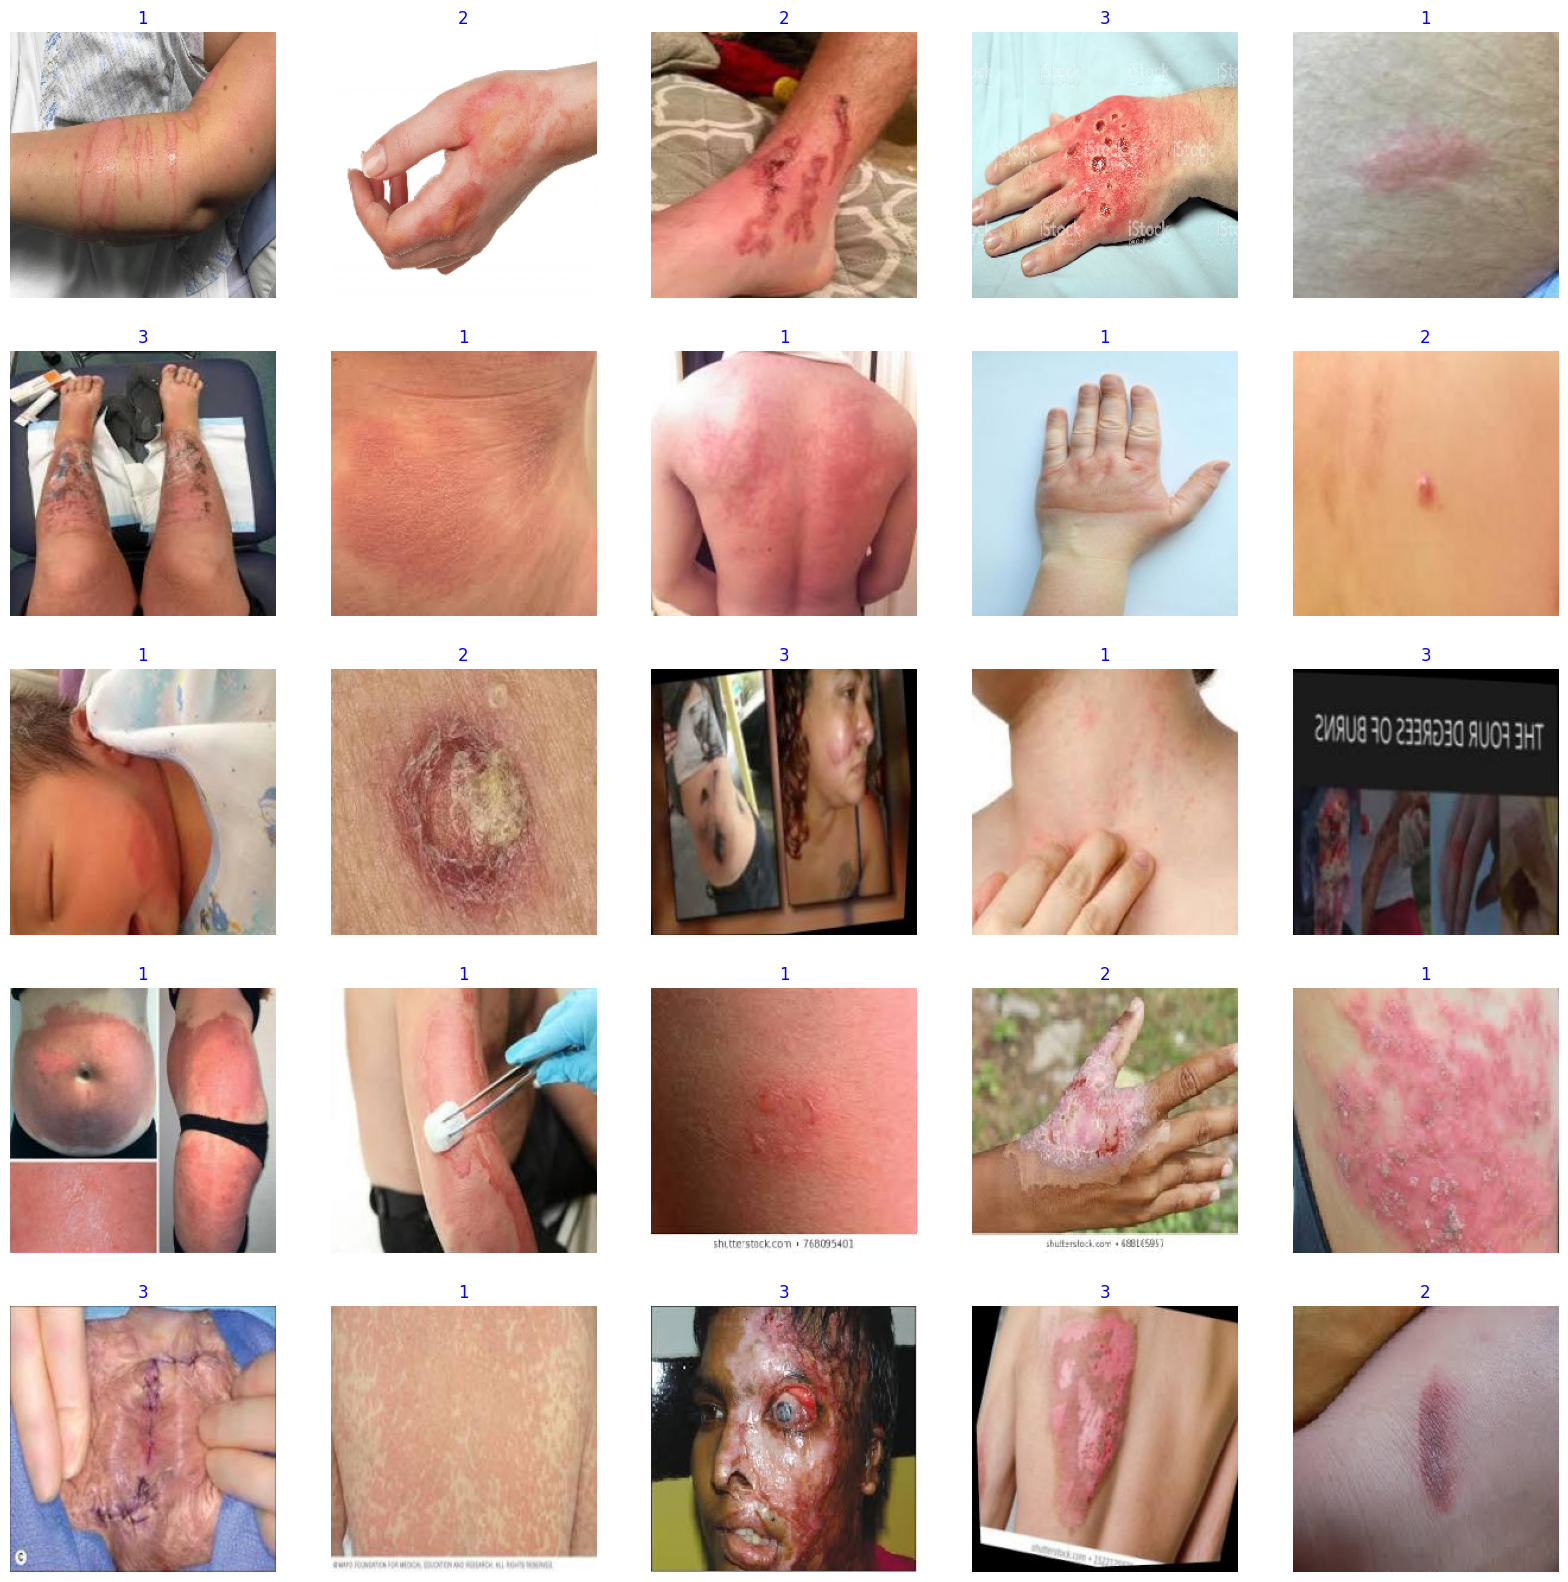

In [13]:
show_images(train_gen)


In [14]:
# Create Model Structure
img_size = (224, 224)
channels = 3
img_shape = (img_size[0], img_size[1], channels)
class_count = len(list(train_gen.class_indices.keys()))  # to define the number of classes in the dense layer

# create pre-trained model (you can build on a pretrained model such as efficientnet, VGG, Resnet)
# we will use efficientnetb3 from the EfficientNet family.
base_model = tf.keras.applications.efficientnet.EfficientNetB3(include_top=False, weights="imagenet", input_shape=img_shape, pooling='max')
base_model.trainable = False
# model = Sequential([
#     base_model,
#     BatchNormalization(axis=-1, momentum=0.99, epsilon=0.001),
#     Dense(256, kernel_regularizer=regularizers.l2(l=0.016), activity_regularizer=regularizers.l1(0.006),
#           bias_regularizer=regularizers.l1(0.006), activation='relu'),
#     Dropout(rate=0.45, seed=123),
#     Dense(class_count, activation='softmax')
# ])

model = Sequential([
    base_model,
    BatchNormalization(axis=-1, momentum=0.99, epsilon=0.001),
    Dense(256, activation='relu', kernel_regularizer=regularizers.l2(l=0.09)),
    Dropout(rate=0.50, seed=123),
    Dense(class_count, activation='softmax')
])

model.compile(Adamax(learning_rate=0.01), loss='categorical_crossentropy', metrics=['accuracy'])

model.summary()



###trying ResNet50
# from tensorflow.keras.applications import ResNet50
# from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, GlobalAveragePooling2D
# from tensorflow.keras.regularizers import l2
# from tensorflow.keras.models import Sequential

# # Create Model Structure
# img_size = (224, 224)
# channels = 3
# img_shape = (img_size[0], img_size[1], channels)
# class_count = len(list(train_gen.class_indices.keys()))  # to define the number of classes in the dense layer

# # create pre-trained model (you can build on a pretrained model such as efficientnet, VGG, Resnet)
# # we will use ResNet50
# base_model = ResNet50(include_top=False, weights="imagenet", input_shape=img_shape)

# model = Sequential([
#     base_model,
#     GlobalAveragePooling2D(),
#     BatchNormalization(),
#     Dense(256, activation='relu', kernel_regularizer=l2(0.01)),
#     Dropout(rate=0.5),
#     Dense(class_count, activation='softmax')
# ])

# model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# model.summary()

###trying vgg19
# from tensorflow.keras.applications import VGG19
# from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, GlobalMaxPooling2D
# from tensorflow.keras.models import Sequential

# # Create Model Structure
# img_size = (224, 224)
# channels = 3
# img_shape = (img_size[0], img_size[1], channels)
# class_count = len(list(train_gen.class_indices.keys()))  # to define the number of classes in the dense layer

# # create pre-trained model (you can build on a pretrained model such as efficientnet, VGG, Resnet)
# # we will use VGG19
# base_model = VGG19(include_top=False, weights="imagenet", input_shape=img_shape)

# model = Sequential([
#     base_model,
#     GlobalMaxPooling2D(),
#     BatchNormalization(),
#     Dense(256, activation='relu', kernel_regularizer=regularizers.l2(l=0.01)),
#     Dropout(rate=0.5, seed=123),
#     Dense(class_count, activation='softmax')
# ])

# model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# model.summary()




Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 efficientnetb3 (Functional  (None, 1536)              10783535  
 )                                                               
                                                                 
 batch_normalization (Batch  (None, 1536)              6144      
 Normalization)                                                  
                                                                 
 dense (Dense)               (None, 256)               393472    
                                                                 
 dropout (Dropout)           (None, 256)               0         
                                                                 
 dense_1 (Dense)             (None, 3)                 771       
                                                                 
Total params: 11183922 (42.66 MB)
Trainable params: 3973

In [15]:
batch_size = 40  # set batch size for training
epochs = 20  # number of all epochs in training
patience = 1  # number of epochs to wait to adjust lr if monitored value does not improve
stop_patience = 3  # number of epochs to wait before stopping training if monitored value does not improve
threshold = 0.9  # if train accuracy is < threshold adjust monitor accuracy, else monitor validation loss
factor = 0.5  # factor to reduce lr by
ask_epoch = 2  # number of epochs to run before asking if you want to halt training
batches = int(np.ceil(len(train_gen.labels) / batch_size))  # number of training batches to run per epoch

callbacks = [MyCallback(model=model, patience=patience, stop_patience=stop_patience, threshold=threshold,
                        factor=factor, batches=batches, epochs=epochs, ask_epoch=ask_epoch)]

In [16]:
history = model.fit(x=train_gen, epochs=epochs, verbose=1, callbacks=callbacks,
                    validation_data=valid_gen, validation_steps=None, shuffle=False)


Do you want model asks you to halt the training [y/n] ?
y
 Epoch     Loss   Accuracy  V_loss    V_acc     LR     Next LR  Monitor  % Improv  Duration
Epoch 1/20
48/48 [==============================] - 247s 5s/step - loss: 9.8280 - accuracy: 0.6302 - val_loss: 2.4081 - val_accuracy: 0.6151
Epoch 2/20
48/48 [==============================] - ETA: 0s - loss: 1.7571 - accuracy: 0.6710 2 /20     1.757   67.103   1.56518  71.757   0.01000  0.01000  accuracy     6.48    14.31  
enter H to halt training or an integer for number of epochs to run then ask again
3
 training will continue until epoch 5
 Epoch     Loss   Accuracy  V_loss    V_acc     LR     Next LR  Monitor  % Improv  Duration
48/48 [==============================] - 19s 365ms/step - loss: 1.7571 - accuracy: 0.6710 - val_loss: 1.5652 - val_accuracy: 0.7176
Epoch 3/20
48/48 [==============================] - 15s 279ms/step - loss: 1.5180 - accuracy: 0.6794 - val_loss: 1.4249 - val_accuracy: 0.7050
Epoch 4/20
48/48 [================

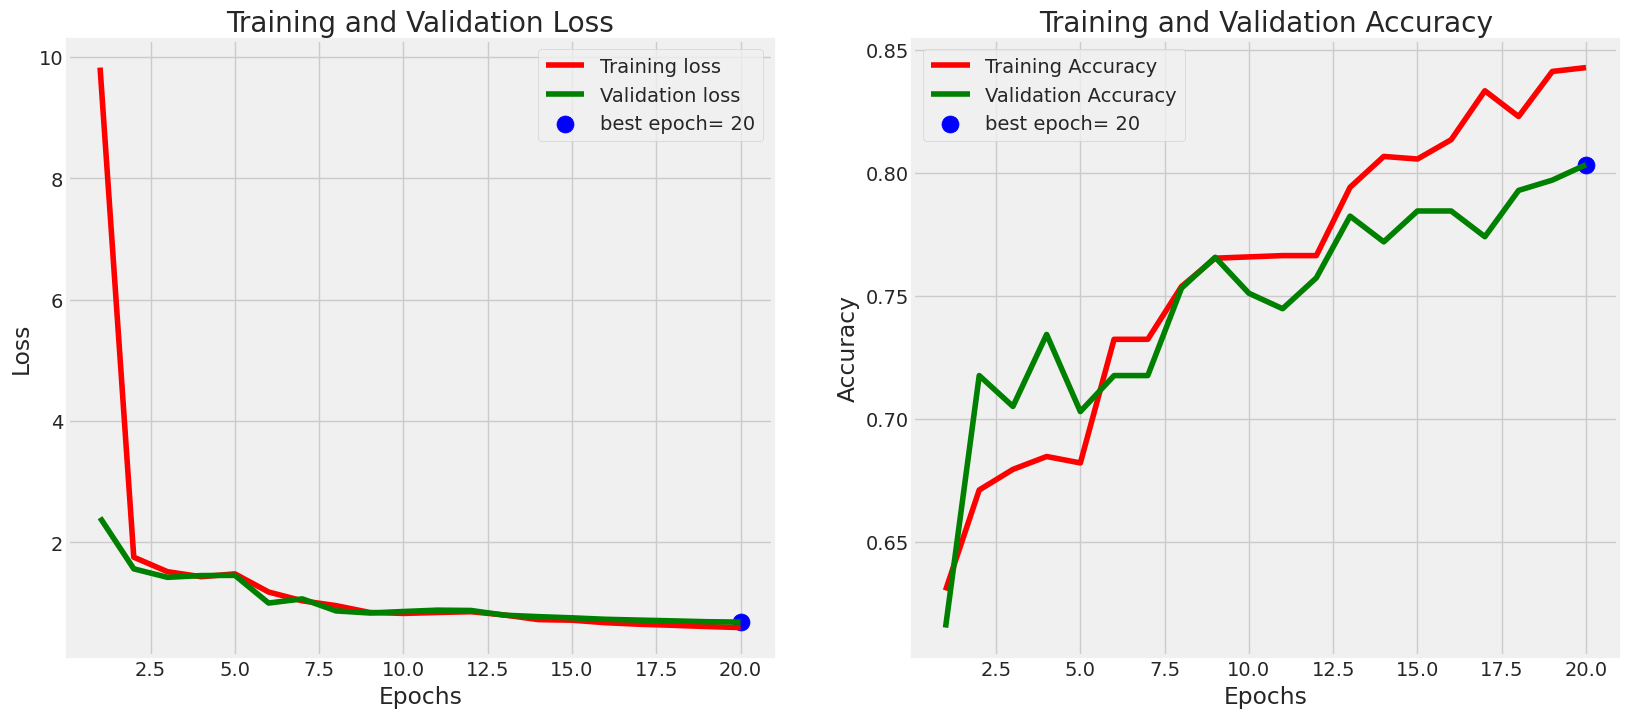

In [17]:
plot_training(history)

In [27]:

# Save model
model_name = "model3"
save_path = "/content/drive/MyDrive"
save_id = str(f'{model_name}.h5')
model_save_loc = os.path.join(save_path, save_id)
model.save(model_save_loc)
print(f'model was saved as {model_save_loc}')

# Save weights
weight_save_id = str(f'{model_name}-weights.h5')
weights_save_loc = os.path.join(save_path, weight_save_id)
model.save_weights(weights_save_loc)
print(f'weights were saved as {weights_save_loc}')

model was saved as /content/drive/MyDrive/model3.h5
weights were saved as /content/drive/MyDrive/model3-weights.h5


In [28]:
# prompt: save a .tflite file

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()

# Save the model.
tflite_model_file = 'converted_model3.tflite'
open(tflite_model_file, 'wb').write(tflite_model)


12168792

In [26]:
# prompt: use the .h5 model on an image resized to 224by224

# Load the model
model = tf.keras.models.load_model('/content/drive/MyDrive/model2.h5')

# Load the image
image = tf.keras.preprocessing.image.load_img('/content/download.jpg', target_size=(224, 224))

# Preprocess the image
image = tf.keras.preprocessing.image.img_to_array(image)
image = np.expand_dims(image, axis=0)

# Make predictions
predictions = model.predict(image)
print(predictions)
# Get the class with the highest probability
predicted_class = np.argmax(predictions)

# Print the predicted class
print(predicted_class)


1/1 [==============================] - 2s 2s/step
[[0.03511532 0.9118873  0.05299733]]
1
